# Initial SNSPD nanohole simulations with pyTDGL

This notebook sets up the initial thesis comparison:

1. Reference superconducting nanowire with **no hole**.
2. The same nanowire with **one circular nanohole**.
3. Comparison of current density and order parameter.
4. A simple current sweep to estimate the onset of instability / critical current.

## Material parameters

The requested coherence length and film thickness are:

- $\xi = 5$ nm
- $d = 8$ nm

The London penetration depth is kept equal to the previous script:

- $\lambda_L = 125$ nm

For this thickness, the corresponding Pearl length is

$$\Lambda = \frac{2\lambda_L^2}{d} \approx 3.91\ \mu\mathrm{m}.$$

The code uses **micrometres as the pyTDGL length unit**, so $\xi=0.005\ \mu$m, $d=0.008\ \mu$m and $\lambda_L=0.125\ \mu$m.

In [2]:
import os
import tempfile
import logging
import numpy as np
import matplotlib.pyplot as plt

import tdgl
from tdgl.geometry import box, circle

from shapely.geometry import Polygon as ShapelyPolygon
from shapely.ops import unary_union

logging.getLogger('tdgl.finite_volume').setLevel(logging.ERROR)

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'


## 1. Physical and numerical parameters


In [3]:
# ============================================================
# MATERIAL PARAMETERS -- all lengths are in micrometres
# ============================================================

xi = 0.005          # 5 nm coherence length
lambda_L = 0.125   # 125 nm London penetration depth (same as previous code)
thickness = 0.008  # 8 nm film thickness

# Pearl length for a thin film:
# Lambda = 2 * lambda_L^2 / thickness
pearl_length = 2 * lambda_L**2 / thickness

print(f'coherence length xi = {xi:.4f} um = {xi*1000:.1f} nm')
print(f'London penetration depth lambda_L = {lambda_L:.4f} um = {lambda_L*1000:.1f} nm')
print(f'film thickness d = {thickness:.4f} um = {thickness*1000:.1f} nm')
print(f'Pearl length Lambda = {pearl_length:.4f} um = {pearl_length*1000:.1f} nm')

# ============================================================
# DEVICE GEOMETRY
# ============================================================

# A narrow SNSPD-like strip.
# Start with dimensions that are computationally manageable.
wire_width = 0.20       # 200 nm
wire_length = 2.00      # 2 um active section
terminal_length = 0.20  # connected lead section at each end

# Single circular hole.
hole_radius = 0.025     # 25 nm radius = 50 nm diameter
hole_x = 0.0
hole_y = 0.0

# Current sweep -- adjust after the first test.
current_values = np.linspace(5, 80, 16)

# ============================================================
# MESH
# ============================================================

# Use 10 nm first for debugging; refine after the geometry works.
max_edge_length = 0.01  # 10 nm = 2 xi

print('\nDimensionless geometry:')
print(f'wire width / xi = {wire_width/xi:.1f}')
print(f'hole diameter / xi = {2*hole_radius/xi:.1f}')
print(f'mesh size / xi = {max_edge_length/xi:.2f}')


coherence length xi = 0.0050 um = 5.0 nm
London penetration depth lambda_L = 0.1250 um = 125.0 nm
film thickness d = 0.0080 um = 8.0 nm
Pearl length Lambda = 3.9062 um = 3906.2 nm

Dimensionless geometry:
wire width / xi = 40.0
hole diameter / xi = 10.0
mesh size / xi = 2.00


### Why this mesh?

The previous `max_edge_length=0.25` was much too coarse for $\xi=5$ nm. Here the initial mesh target is **2.5 nm = 0.5$\xi$**. This is deliberately conservative for vortex/order-parameter simulations.

After the first simulations, perform a convergence test with approximately 5 nm, 2.5 nm and 1.25 nm maximum edge lengths. The final thesis simulations should use the coarsest mesh that gives converged quantities such as $I_c$ and vortex-entry location.

## 2. Construct the nanowire


In [4]:
def make_device(with_hole=False, mesh_edge_length=max_edge_length):
    """Create a connected rectangular strip with optional hole and terminals."""

    def resample_boundary(polygon, num_points):
        points = polygon.resample(num_points).points

        if np.allclose(points[0], points[-1]):
            points = points[:-1]

        return tdgl.Polygon(polygon.name, points=points)

    layer = tdgl.Layer(
        coherence_length=xi,
        london_lambda=lambda_L,
        thickness=thickness,
    )

    total_length = wire_length + 2 * terminal_length
    film = resample_boundary(
        tdgl.Polygon(
            'film',
            points=[
                (-wire_width / 2, -total_length / 2),
                ( wire_width / 2, -total_length / 2),
                ( wire_width / 2,  total_length / 2),
                (-wire_width / 2,  total_length / 2),
            ],
        ),
        100,
    )

    holes = []
    if with_hole:
        hole = resample_boundary(
            tdgl.Polygon(
                'hole',
                points=circle(hole_radius),
            ).translate(dx=hole_x, dy=hole_y),
            48,
        )
        holes.append(hole)

    terminal = box(wire_width, terminal_length)
    source = tdgl.Polygon('source', points=terminal).translate(
        dy=total_length / 2,
    )
    drain = tdgl.Polygon('drain', points=terminal).translate(
        dy=-total_length / 2,
    )

    probe_points = [
        (0.0, -wire_length / 4),
        (0.0,  wire_length / 4),
    ]

    device = tdgl.Device(
        'nanowire_hole' if with_hole else 'nanowire_no_hole',
        layer=layer,
        film=film,
        holes=holes,
        terminals=[source, drain],
        probe_points=probe_points
    )

    device.make_mesh(
        max_edge_length=mesh_edge_length,
        smooth=0,
    )

    return device

## 3. Visualize the two geometries


Constructing Voronoi polygons: 100%|██████████| 17368/17368 [00:00<00:00, 19147.99it/s]


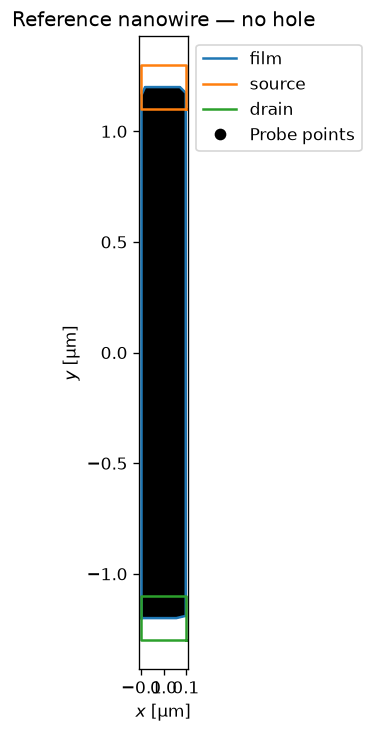

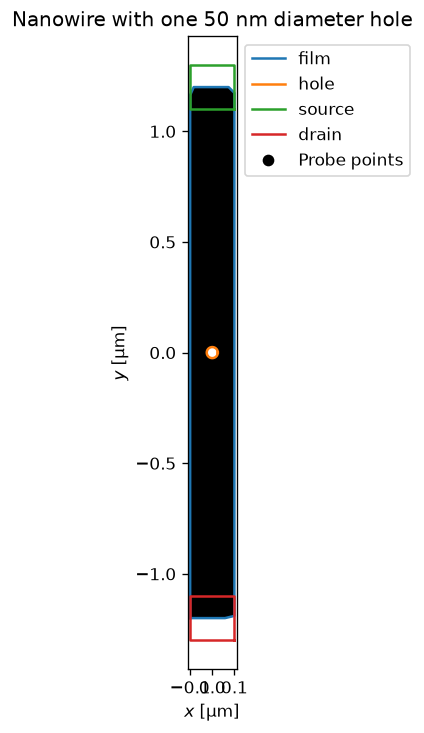

In [5]:
device_no_hole = make_device(with_hole=False)
device_one_hole = make_device(with_hole=True)

fig, ax = device_no_hole.plot(mesh=True)
ax.set_aspect('equal')
ax.set_title('Reference nanowire — no hole')
plt.show()

fig, ax = device_one_hole.plot(mesh=True)
ax.set_aspect('equal')
ax.set_title(f'Nanowire with one {2*hole_radius*1000:.0f} nm diameter hole')
plt.show()


## 4. Run one reference simulation

For the initial geometry study we deliberately use **no magnetic self-screening**. This makes the parameter sweep much faster. Screening can later be enabled for the final candidate geometries.

In [6]:
def run_simulation(device, current, include_screening=False, solve_time=80):
    """Run a TDGL simulation and return the solution."""

    tempdir = tempfile.TemporaryDirectory()

    options = tdgl.SolverOptions(
        skip_time=20,
        solve_time=solve_time,
        output_file=os.path.join(tempdir.name, 'solution.h5'),
        include_screening=include_screening,
        dt_max=1e-3,
    )

    solution = tdgl.solve(
        device,
        options,
        applied_vector_potential=0.0,
        terminal_currents={
            'source': current,
            'drain': -current,
        },
    )

    # Keep the TemporaryDirectory alive by attaching it to the solution.
    solution._tdgl_tempdir = tempdir

    return solution


Simulating: 100%|█████████▉| 80/80 [08:34<00:00,  6.43s/tau ]     


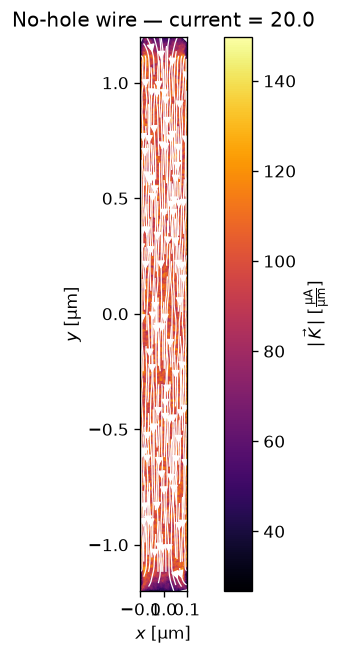

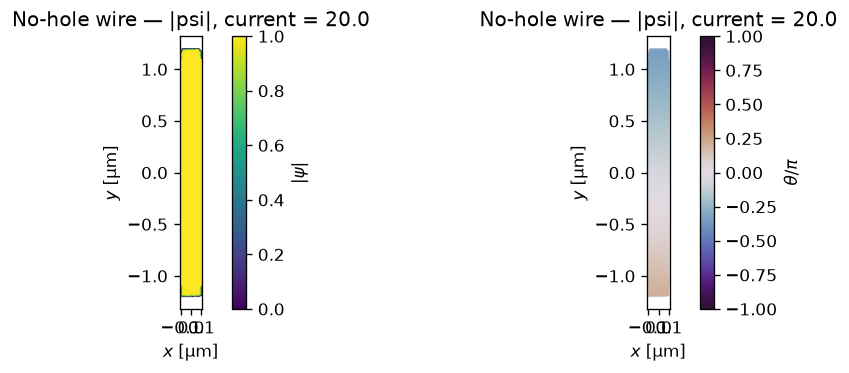

In [7]:
# Start with a moderate current rather than immediately running the whole sweep.
test_current = 20.0

solution_no_hole = run_simulation(
    device_no_hole,
    current=test_current,
    include_screening=False,
)

fig, ax = solution_no_hole.plot_currents()
ax.set_title(f'No-hole wire — current = {test_current}')
plt.show()

result = solution_no_hole.plot_order_parameter()
if isinstance(result, tuple):
    fig, axes = result
else:
    fig, axes = plt.gcf(), result

try:
    axes_list = axes.flat
except AttributeError:
    axes_list = [axes]

for ax in axes_list:
    ax.set_title(f'No-hole wire — |psi|, current = {test_current}')

plt.show()


## 5. Run the single-hole geometry


Simulating: 100%|█████████▉| 80/80 [05:07<00:00,  3.85s/tau ]


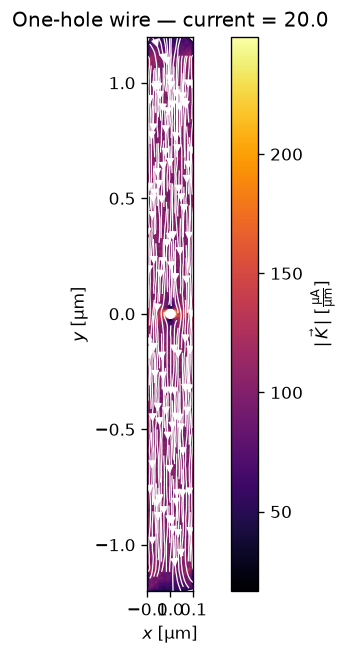

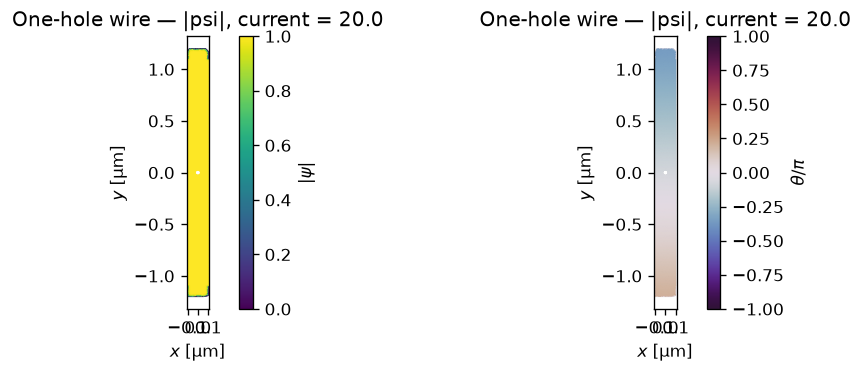

In [8]:
solution_one_hole = run_simulation(
    device_one_hole,
    current=test_current,
    include_screening=False,
)

fig, ax = solution_one_hole.plot_currents()
ax.set_title(f'One-hole wire — current = {test_current}')
plt.show()

result = solution_one_hole.plot_order_parameter()
if isinstance(result, tuple):
    fig, axes = result
else:
    fig, axes = plt.gcf(), result

try:
    axes_list = axes.flat
except AttributeError:
    axes_list = [axes]

for ax in axes_list:
    ax.set_title(f'One-hole wire — |psi|, current = {test_current}')

plt.show()


## 6. Compare the current-density distributions

The first qualitative question is whether the hole redistributes current strongly enough to create a reproducible current-crowding region. This is the first step toward identifying a geometry that can alter vortex-entry behavior.

## 7. Simple current sweep

This is deliberately a coarse exploratory sweep. The exact critical current should later be determined with a finer bracket around the transition and with a physically justified instability criterion.

In [9]:
def current_sweep(device, currents, include_screening=False, solve_time=60):
    results = []

    for I in currents:
        print(f'Running I = {I:.2f} ...')
        sol = run_simulation(
            device,
            current=float(I),
            include_screening=include_screening,
            solve_time=solve_time,
        )

        # Access the final order parameter if available.
        # This gives a simple screening diagnostic; use a more rigorous
        # criterion for the final thesis analysis.
        psi = sol.tdgl_data.psi

        if psi is None:
            raise RuntimeError("The solution contains no order-parameter data.")

        results.append({
            'current': I,
            'min_abs_psi': np.min(np.abs(psi)),
            'mean_abs_psi': np.mean(np.abs(psi)),
        })

    return results


In [10]:
# Uncomment when the single simulations above work correctly.
# Start with a very small sweep.

currents_test = np.array([10, 20, 30, 40, 50])
no_hole_results = current_sweep(device_no_hole, currents_test, include_screening=False)
hole_results = current_sweep(device_one_hole, currents_test, include_screening=False)

print(no_hole_results)
print(hole_results)


Running I = 10.00 ...


Simulating: 100%|█████████▉| 60/60 [03:32<00:00,  3.53s/tau ]


Running I = 20.00 ...


Simulating: 100%|█████████▉| 60/60 [03:45<00:00,  3.75s/tau ]


Running I = 30.00 ...


...

Running I = 40.00 ...


Simulating: 100%|█████████▉| 60/60 [03:58<00:00,  3.98s/tau ]


Running I = 50.00 ...


Simulating: 100%|█████████▉| 60/60 [03:50<00:00,  3.84s/tau ]


[{'current': np.int64(10), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9890538480144155)}, {'current': np.int64(20), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9890491318809466)}, {'current': np.int64(30), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9890412712210838)}, {'current': np.int64(40), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9890302653730842)}, {'current': np.int64(50), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9890161134154473)}]
[{'current': np.int64(10), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.989221513160094)}, {'current': np.int64(20), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9892167225360454)}, {'current': np.int64(30), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9892087377051595)}, {'current': np.int64(40), 'min_abs_psi': np.float64(0.0), 'mean_abs_psi': np.float64(0.9891975579831904)}, {'current': np.int64(50), 'min_abs_p

## 8. Mesh-convergence test

For the thesis, do not choose the mesh only from computational convenience. Check that the quantities of interest converge.

Recommended first test:

| Maximum edge | Relative to $\xi$ |
|---:|---:|
| 5 nm | $1.0\xi$ |
| 2.5 nm | $0.5\xi$ |
| 1.25 nm | $0.25\xi$ |

For each mesh, compare the estimated critical current and the position/shape of the current-crowding region. The final mesh should be chosen after convergence rather than simply choosing the finest mesh.

In [12]:
mesh_values = [0.005, 0.0025, 0.00125]  # 5, 2.5, 1.25 nm

for h in mesh_values:
    dev = make_device(with_hole=True, mesh_edge_length=h)
    print(h, len(dev.mesh.sites), len(dev.mesh.elements))


Constructing Voronoi polygons: 100%|██████████| 70918/70918 [00:03<00:00, 19796.30it/s]


0.005 70918 140208


Constructing Voronoi polygons: 100%|██████████| 277509/277509 [00:13<00:00, 20044.27it/s]


0.0025 277509 551763


Constructing Voronoi polygons: 100%|██████████| 1170545/1170545 [01:04<00:00, 18077.13it/s]


0.00125 1170545 2334551


## 9. Screening comparison for the final geometry

Once the no-screening simulations are understood, repeat the same calculation with

```python
include_screening=True
```

and compare the results. Do not assume screening is negligible solely from the Pearl length; verify it for the geometry and current range used in the thesis.

In [13]:
# Example final-geometry comparison:
#
screening_solution = run_simulation(
    device_one_hole,
    current=test_current,
    include_screening=True,
    solve_time=80,
)

fig, ax = screening_solution.plot_currents()
ax.set_title('One-hole wire — self-field screening included')
plt.show()


Thermalizing:   0%|          | 0/20 [01:01<9:09:18, 1650.98s/tau ]


AttributeError: 'NoneType' object has no attribute '_tdgl_tempdir'

# Suggested thesis progression

The next simulations should systematically vary **one parameter at a time**:

1. No hole — determine reference $I_c$.
2. One hole — determine how $I_c$ and current crowding change.
3. Hole diameter: e.g. 20, 40, 60, 80 nm.
4. Hole position across the wire width.
5. Hole position along the wire.
6. Compare current-density enhancement around the hole.
7. Investigate vortex-entry location.
8. Repeat the most relevant geometries with self-field screening.

The key quantities to extract are $I_c$, maximum current density, minimum $|\psi|$, vortex-entry position, and—later—photon-induced/vortex-induced dynamics.